<a href="https://colab.research.google.com/github/freddyjosephthanikkal/Deep_Learning/blob/main/Image_Classification_Using_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
keras.utils.set_random_seed(42)

*   The seed is there so that every time we run these tests, the results will be the similar.




In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


*   (60k images) x_train, y_train -> Kept for Training the Model.
*   (10k images) x_test, y_test -> For testing the Model.
*   All images are 28*28 pixels -> 70k images in total, 10 different categories
*   x -> input data, y -> expected output.








In [3]:
print(x_train.shape, y_train.shape)

(60000, 28, 28) (60000,)


* x(training) -> 60000 nos * (28*28 pixels)
* y(training) -> 60000 single row
* (60000,) -> means its a single row or array [0,1,2,3...,59999]
* (60000,1) -> means its a 60000 rows with a single column ([0],[1],[2],[3],.....,[59999])


In [4]:
print(x_test.shape, y_test.shape)

(10000, 28, 28) (10000,)


In [5]:
y_train[:10]
print(y_train[10:20])
print(y_train[:].shape)

[0 9 5 5 7 9 1 0 6 4]
(60000,)


* python slicing -> array[start:stop] -> syntax
* y_train[:10] == y_train[0:10] -> first 10 training list out of the 60000

In [6]:
labels = ["T-shirt/top",
          "Trouser",
          "Pullover",
          "Dress",
          "Coat",
          "Sandal",
          "Shirt",
          "Sneaker",
          "Bag",
          "Ankle boot"]

* The categories are labelled.

In [7]:
labels[y_train[0]]

'Ankle boot'

* List the Category of the first item in the training dataset.

In [8]:
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 23

* Print the 28*28 pixel greyscale intensity numerals as a matrix.

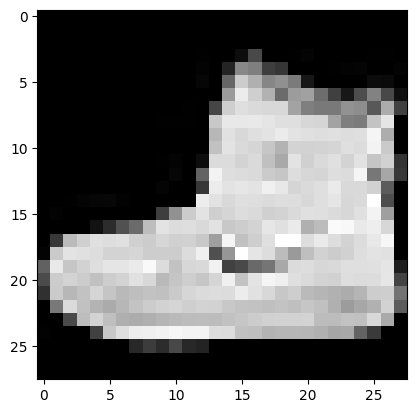

In [9]:
plt.imshow(x_train[0], cmap="gray")
plt.show()

* Show the first image as a greyscale from the training data.

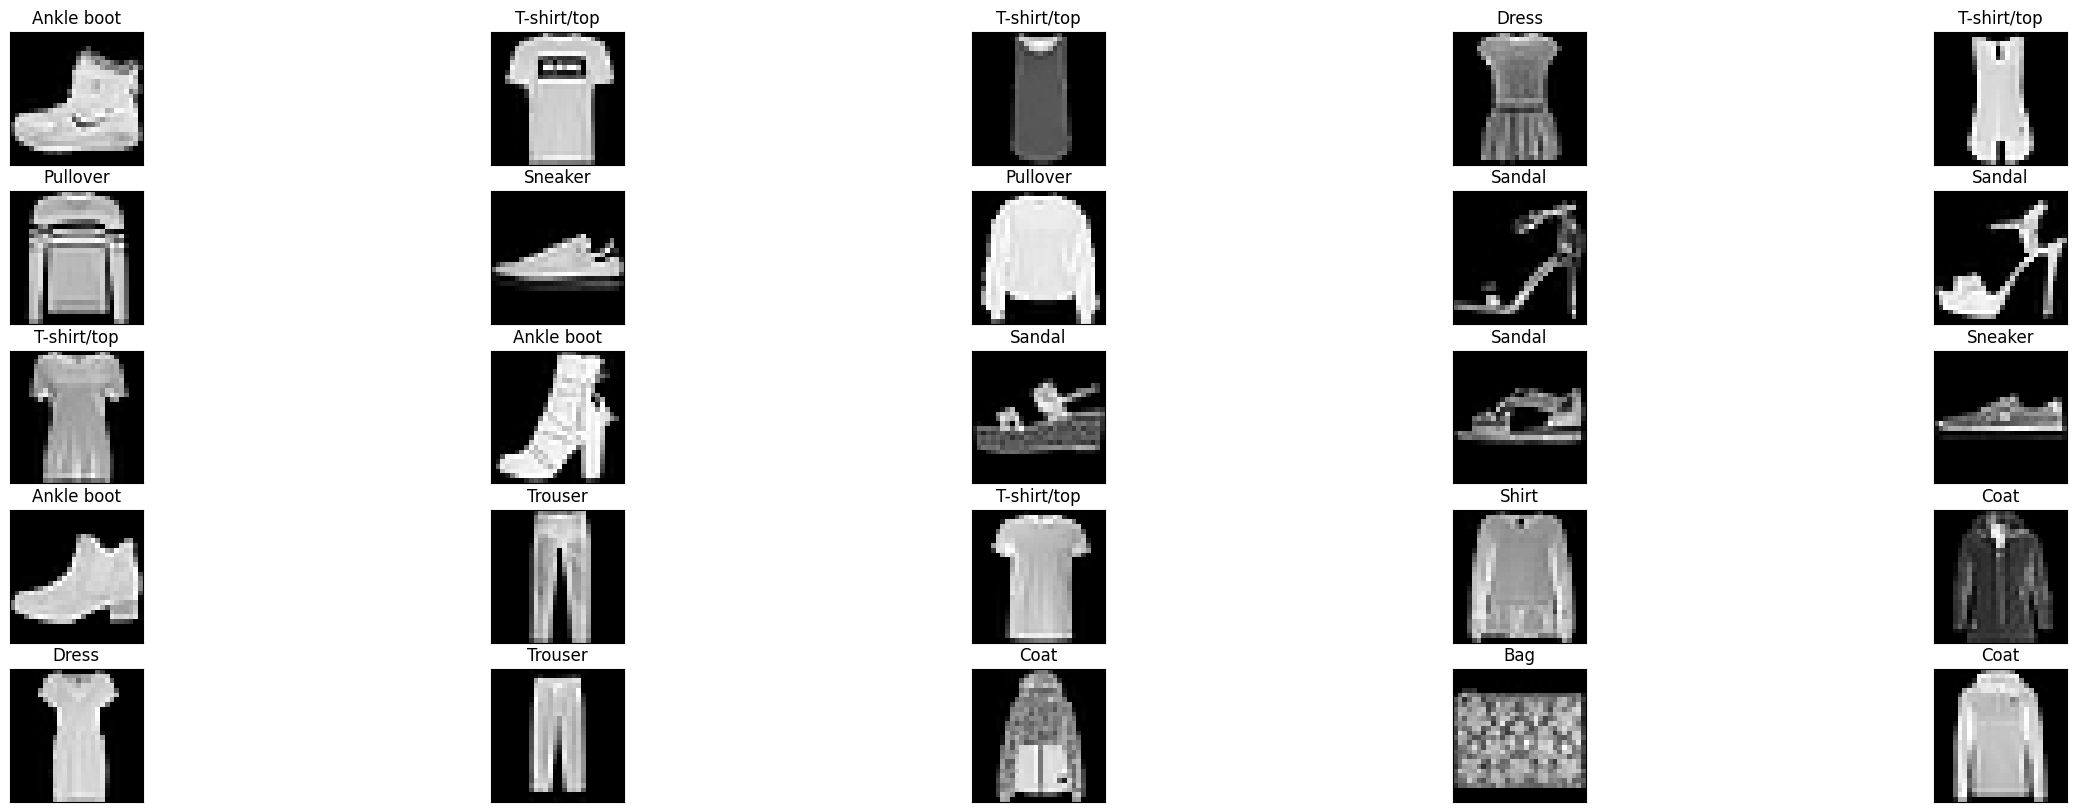

In [10]:
fig, ax = plt.subplots(5, 5, figsize=(30, 10))
for i in range(25):
  axc = ax[i//5, i%5]
  axc.imshow(x_train[i], cmap="gray")
  axc.set_title(f"{labels[y_train[i]]}")
  axc.set_xticks([])
  axc.set_yticks([])

* plt.subplots -> create a subplot
* fig -> the overall canvas
* ax -> individual plots
* (5,5) -> 5 rows and 5 columns
* fig size = (30,10) -> overall image size in inches. (30*10) inches
* Let the i = 7: ax[i//5, i%5] -> ax[7//5, 7%5] ->ax[1,2]
* 1,2 is the position of the image 7
* axc.imshow(x_train[i], cmap="gray") -> display the image as greyscale.
* (f"{labels[y_train[7]]}") -> Let i be 9 -> f"{label[9]}" -> Angle Boot -> The image in the 7th position corresponds to the label 9 in categories.

In [11]:
def plot_loss_curves(history):
  plt.clf()
  history_dict = history.history
  loss_values = history_dict["loss"]
  val_loss_values = history_dict["val_loss"]
  epochs = range(1, len(loss_values) + 1)
  plt.plot(epochs, loss_values, "bo", label="Training loss")
  plt.plot(epochs, val_loss_values, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()

* clf -> Clear Figure -> Start with a clean canvas
* history.history -> history contains attributes -> variables.attributes
* history_dict -> takes the objects/attributes in the history to a new variable history_dict
* It contains items like loss, accuracy, Validation loss and accuracy
* Plots -> Take Training loss and validation loss and plot it against the number of epochs
* bo -> Blue circular mark
* b -> Blue solid line
* legend -> shows the labels -> Training Loss and Validation Loss
* x axis -> epoch, y axis -> loss value

In [12]:
def plot_acc_curves(history):
  plt.clf()
  history_dict = history.history
  acc = history_dict["accuracy"]
  val_acc = history_dict["val_accuracy"]
  epochs = range(1, len(acc) + 1)
  plt.plot(epochs, acc, "bo", label="Training acc")
  plt.plot(epochs, val_acc, "b", label="Validation acc")
  plt.title("Training and validation accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

In [13]:
x_train = x_train/ 255.0
x_test = x_test/ 255.0

* data/255 -> converting the intensity from 0 -> 255 to 0-> 1 for making it consistent and the multiplied value to be smaller.

In [14]:
x_train.shape

(60000, 28, 28)

* The shape is currently (60000,28,28) -> we need to make that 28 * 28 * 1 for future for RGB images.
* The additional number is for color channels

In [15]:
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

* np.expand_dims(x_train, -1) -> the -1 adds an additional dimension to the existing one.

In [16]:
x_train.shape

(60000, 28, 28, 1)

In [17]:
input = keras.Input(shape=x_train.shape[1:])
x = keras.layers.Conv2D(32,kernel_size=(2, 2),activation="relu",name="Conv_1")(input)
x = keras.layers.MaxPool2D()(x)
x = keras.layers.Conv2D(32,kernel_size=(2, 2),activation="relu",name="Conv_2")(x)
x = keras.layers.MaxPool2D()(x)
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(256, activation="relu")(x)
output = keras.layers.Dense(10, activation="softmax")(x)
model = keras.Model(input, output)

* Input layer -> Convolutional layer 1 -> Max pooling 1 -> Convolutional layer 2 -> Max pooling 2 -> Flatten -> Dense layer -> Output layer
* x_train.shape[1:] -> Take everything after the 60000 -> 28 * 28 * 1 -> take the image data
* Conv2D(32) -> Use 32 different convolution filters
* kernel_size = (2,2) -> Each filter is 2*2 covering pixel data
* For greyscale it is 2 * 2 * 1 -> for RGB it is 2 * 2 * 3
* The output will be of (((28-2)/1)+1) = 27 -> Outputs a 27*27*32 layered feature map
* ReLU is used after the convolution for positive results.
* MaxPool2D()(x) -> Use the Maxpool here -> For downsampling/ reducing the size -> Taking the largest number in the 2*2 grid across every feature map -> useful for reducing the computation.
* reduce the size from 27 * 27 * 32 to 13*13*32
* After the second convolution it becomes -> 12 * 12 * 32
* After the second MaxPool -> 6 * 6 * 32
* Flatten()(x) -> converts the entire 3D to a 1D vector -> 6 * 6 * 32 = 1152 values
* Dense(256, activation="relu")(x) -> Dense - 256 interconnected neurons -> uses ReLU.
* Dense(10, activation="softmax")(x) -> the output layer is softmax -> so that the total adds upto 1
* keras.Model(input, output) -> create the model -> Connect to the keras model

In [18]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_1 (Conv2D)                 │ (None, 27, 27, 32)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 12, 12, 32)     │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302,026 (1.15 MB)

 Trainable params: 302,026 (1.15 MB)

 Non-trainable params: 0 (0.00 B)

* Conv_1
32 filters, each with a 2 × 2 kernel and one input channel.
(2 × 2 × 1 × 32) + 32 = 160
* Conv_2
Now there are 32 input channels and 32 filters.
(2 × 2 × 32 × 32) + 32 = 4128
* Dense layer
Flatten output contains 1,152 values, connected to 256 neurons.
(1152 × 256) + 256 = 295168
* Output layer
256 inputs connected to 10 output neurons.
(256 × 10) + 10 = 2570

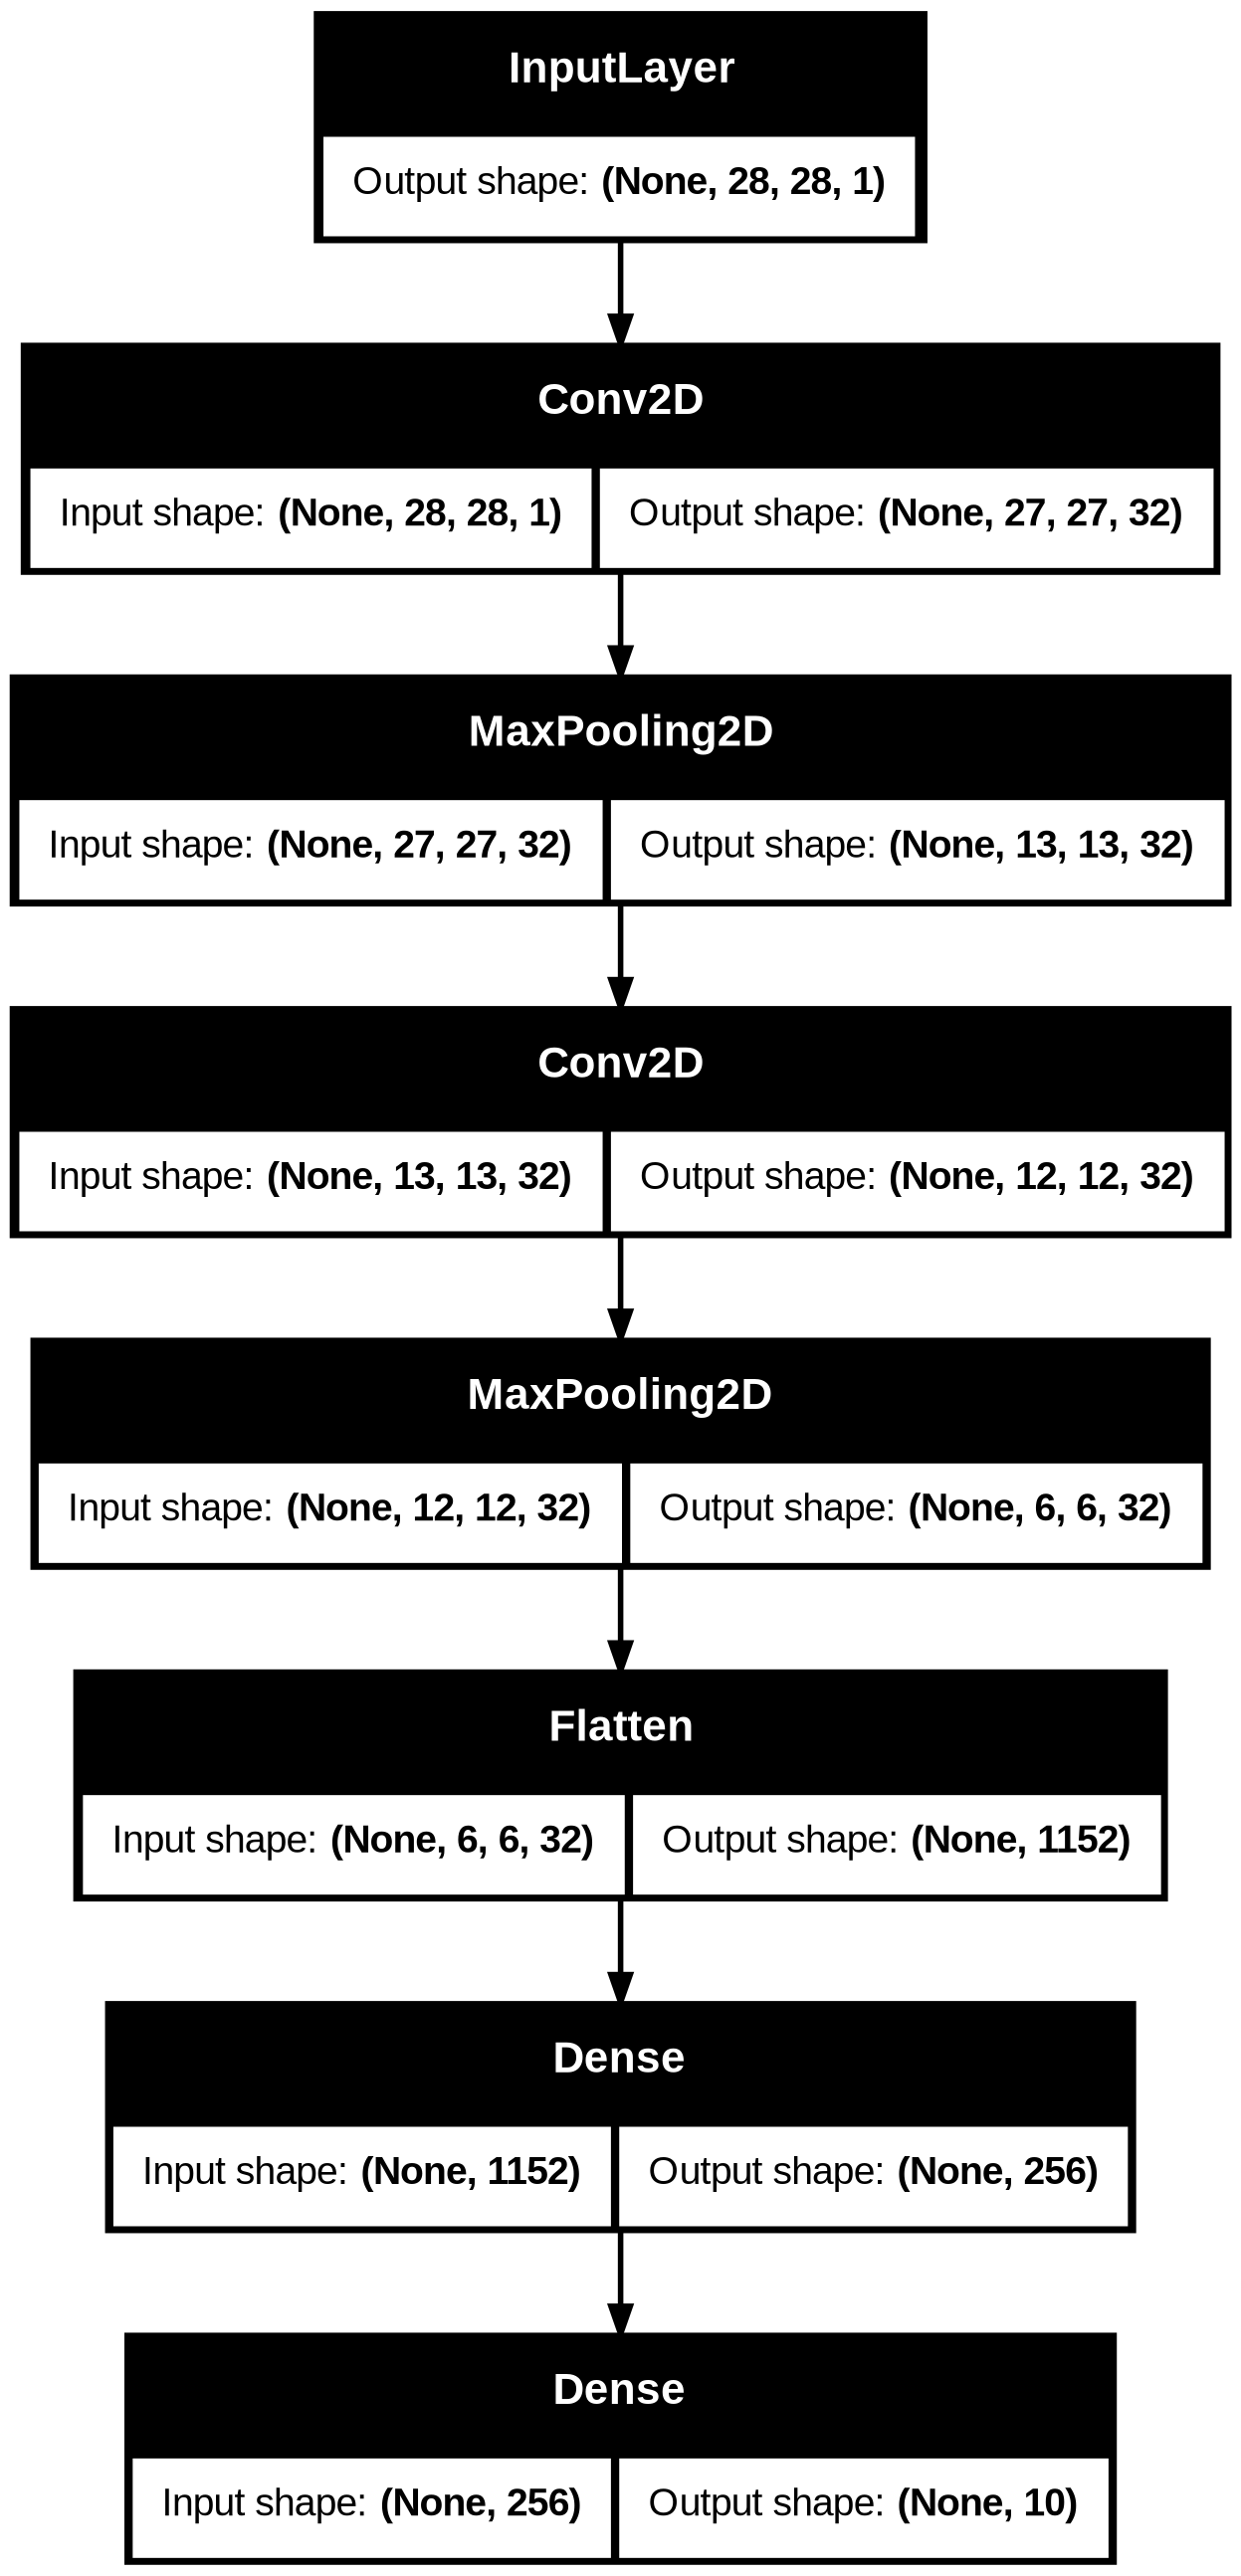

In [19]:
keras.utils.plot_model(model, show_shapes=True)

* show_shapes=True -> It tells Keras to display the output dimensions of every layer.

In [20]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

* sparse_categorical_crossentropy -> calculates the loss for the output -> Loss = - log(Probablitiy)
* adam -> after the loss calculation adam optimizer is used to adjust the weights and biases while backpropagating -> also updates the Convolution layer.
* metrics=["accuracy"] -> This tells Keras to calculate classification accuracy while training and evaluating the model.

In [21]:
history = model.fit(x_train,
                    y_train,
                    batch_size=64,
                    epochs=10,
                    validation_split=0.2)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - accuracy: 0.8152 - loss: 0.5090 - val_accuracy: 0.8706 - val_loss: 0.3706
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 30s 40ms/step - accuracy: 0.8780 - loss: 0.3396 - val_accuracy: 0.8871 - val_loss: 0.3100
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 41ms/step - accuracy: 0.8946 - loss: 0.2900 - val_accuracy: 0.8964 - val_loss: 0.2808
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 41ms/step - accuracy: 0.9043 - loss: 0.2578 - val_accuracy: 0.9010 - val_loss: 0.2648
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 29s 39ms/step - accuracy: 0.9141 - loss: 0.2330 - val_accuracy: 0.9047 - val_loss: 0.2577
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 40ms/step - accuracy: 0.9224 - loss: 0.2115 - val_accuracy: 0.9064 - val_loss: 0.2581
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 30s 40ms/step - accuracy: 0.9289 - loss: 0.1920 - val_accuracy: 0.9068 - val_loss: 0.2594
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 29s 39ms/step - accuracy: 0.9361 - loss: 0.1738 - 

* model.fit(...) -> starts the training.
* validation_split=0.2 -> Reserve the 20% of training data for validating the training data.
* batch_size=64 -> 64 images are processed togather -> The training is done as sets/batches -> (60000-20% of 60000)/64 = (48000/64) = 750 batches per epoch
* epochs=10 -> The entire training happens 10 times -> So we get 750 * 10 = 7500 batches in total.
* Everything is stored inside the history variable.

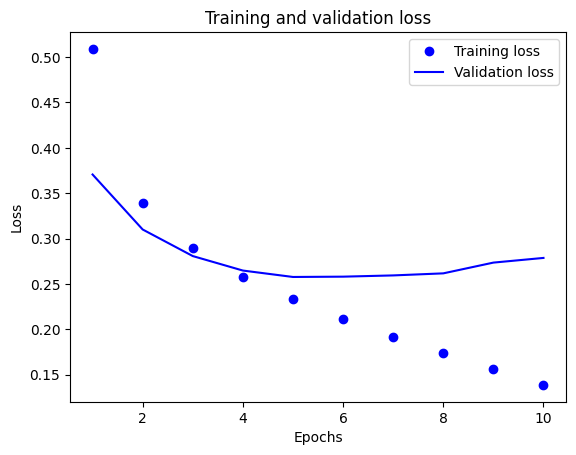

In [22]:
plot_loss_curves(history)

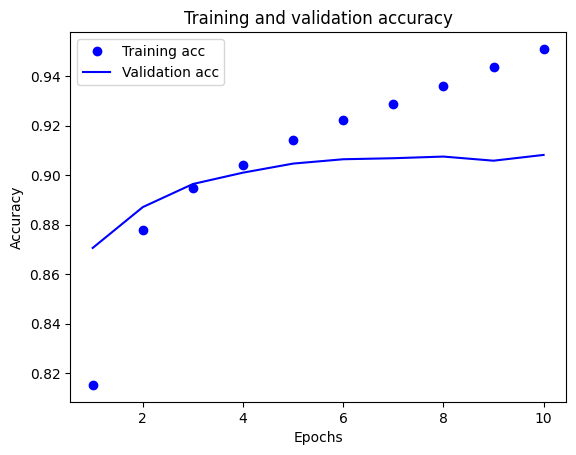

In [23]:
plot_acc_curves(history)

In [24]:
score = model.evaluate(x_test, y_test)
print("Test accuracy:", score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8984 - loss: 0.2905
Test accuracy: 0.8984000086784363


* model.fit() -> Trains the model and updates weights.
* model.evaluate() -> Measures performance on supplied data -> We get the Loss and accuracy
* model.predict() -> Generates predictions for supplied data.
